In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft, ifft, fftfreq, ifftn
import scipy
from scipy import stats, signal, misc
from scipy.stats import norm
import matplotlib.dates as mdates
%matplotlib inline
from pandas import DataFrame
from datetime import datetime, timedelta
import calendar
from pytz import timezone
import seaborn as sns
import imageio
import os
import matplotlib.image as mpimg
import warnings # Will be used to ignore the unnecessary warning so that the code look good esthetically
warnings.filterwarnings('ignore')
import statsmodels.api as sm
from statsmodels.tsa.ar_model import AutoReg,ARResults
from statsmodels.tsa.statespace.tools import diff
from statsmodels.tsa import ar_model



<a id='AR'></a>
### AR(p) (Auto Regressive Models)
[Autoregressive (AR(p)) models](https://otexts.com/fpp2/AR.html) are models which use previous values to predict the current value (or guess the next one) of the same variable. They are like regression models, but instead of using lagged values of the variable itself as a predictor. The number of previous values used is called the **`order`** of the AR model. 

AR(p) models have the following form: 

$
X_t=c+\sum_{i=1}^{p} \phi_i X_{t-i}+\epsilon_t
$

where $\phi_i$ are parameters that depend on the order of the AR model, $c$ is a constant and $\epsilon_t$ is random, white noise, error. Error terms $\varepsilon_t$ are generally assumed to be independent identically distributed random variables (i.i.d.) sampled from a normal distribution with zero mean: $\varepsilon _{t} ~ N(0,\sigma^2)$ where $\sigma^2$ is the variance. 

Given that definition, the expanded form of AR(1) would be for $X_t$:

$
X_t = c + (\phi_1)X_{t-1} + \epsilon_t
$

and AR(2) would be

$
X_t = c + \phi_1 X_{t-1} + \phi_2 X_{t-2}  + \epsilon_t
$

etc. 

The expanded forms show clearly how the current value $X_t$ is obtained from the lagged values $X_{t-i}$.

Now let's also expand the form of $X_{t-1}$. AR(1) for $X_{t-1}$ would be

$
X_{t-1} = c + \phi_1 X_{t-2}  + \epsilon_{t-1}
$

So we can say that 

$
X_t = c + (\phi_1) \left(c + \phi_1 X_{t-2}  + \epsilon_{t-1} \right) + \epsilon_t
$

which we could rewrite as

$
X_t = c^* + (\phi_1)^2 X_{t-2}  + \phi_1 \epsilon_{t-1} + \epsilon_t
$

and we see that $X_t$ is not only dependent on $X_{t-1}$, but also on $X_{t-2}$ since $X_{t-1}$ did depend on it. In fact, we can show that 

$
X_t = \frac{c}{1-\phi} + (\phi_1)^t X_{1}  + \phi_1^{t-1} \epsilon_{2} + \phi_1^{t-2} \epsilon_{3}+ ... + \epsilon_t
$

and we see that the current value of $X_t$, to a very small degree (i.e. through $\phi^t$, does actually depend, in a small way, even on the very first value of the data series, $X_1$). For this reason, we say that AR models are [`long memory models`](https://www.youtube.com/watch?v=Mc6sBAUdDP4&t=3s). 

AR models can be restricted to stationary data if the parameters $\phi$ [obey certain rules](https://otexts.com/fpp2/AR.html):
- For AR(1): $-1 < \phi < 1$
- For AR(2): $-1 < \phi_2 < 1, \phi_1 + \phi_2 <1, \phi_2 - \phi_1 <1$

for p>2, restrictions are more complicated. Algorithms typically take care of these rules automatically when estimating AR models (i.g. fitting $\phi$ values). 

To illustrate AR models, let's try to code a dummy one here: 

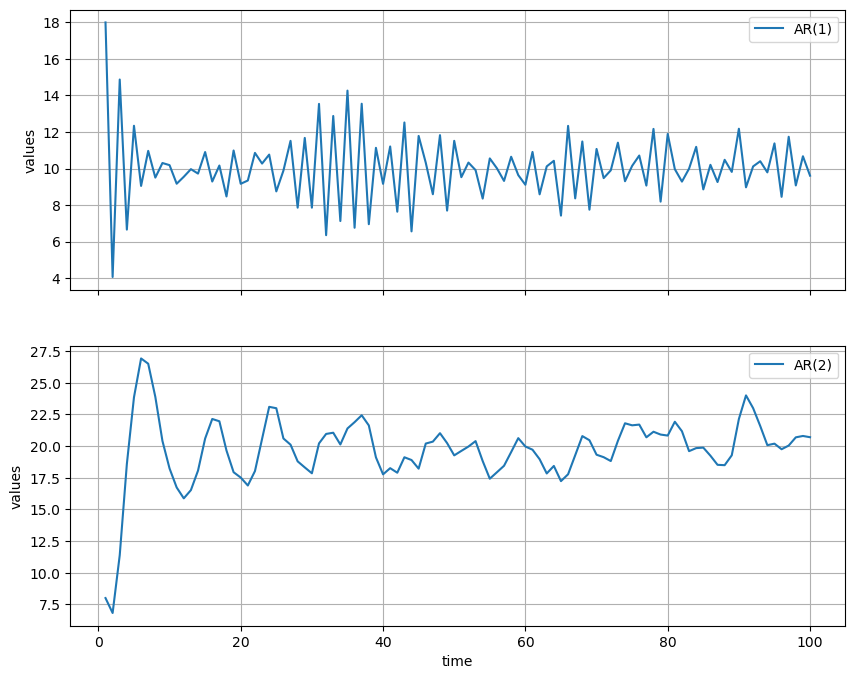

In [3]:
# create some indices for a hypotetical time series (that will be our "time-axis")
L=100 # set the number of time steps
t = [i for i in range(1,L+1)]

# Create normally distributed random number, with mean=0, and variance 1, or 0.8
mu, sigma0, sigma1 = 0, 2, 1
AR1_0 = np.random.normal(mu,sigma0,1)
epsilon = np.random.normal(mu,sigma1,L)

# initialize some arrays to collect the results
AR1 = np.zeros((L,1))
AR2 = np.zeros((L,1))

# initialize AR1_t-1 with any number to start the iteration
AR1[0]=18 

# initialize AR2_t-1 and AR2_t-2 with any numbers to start the iteration
AR2[0]=8
AR2[1]=AR2[0]+AR1_0


# time step a made up AR(1) model, starting from index 1 (t), not 0 (0 is t-1)
for i in range(1,L):
    AR1[i] = 18 - 0.8*AR1[i-1] + epsilon[i]

# time step a made up AR(2) model, starting from index 2 (t), not 1, 0 (1 is t-1; 0 is t-2)
for i in range(2,L):
    AR2[i] = 8 + 1.3*AR2[i-1] - 0.7*AR2[i-2] + epsilon[i]
    
# Plot it using a custom function
fig, (ax0, ax1) = plt.subplots(nrows=2, sharex=True, figsize=(10,8))

ax0.plot(t[0:100],AR1[0:100], label="AR(1)") 
ax0.legend()
ax0.grid()
ax0.set_ylabel('values')
  
ax1.plot(t[0:100],AR2[0:100], label="AR(2)") 
ax1.legend()
ax1.grid()
ax1.set_ylabel('values')
ax1.set_xlabel('time')

plt.show()    


<a id='MA'></a>
### MA(q) (Moving Average Models)

[Moving average (MA(q)) model](https://otexts.com/fpp2/MA.html) use past errors in the model to predict future values. The “order” of an MA model refers to how many steps are taken back in time to predict the next value.

$
X_t=\mu + \epsilon_t + \sum_{i=1}^{q} \theta_i \epsilon_{t-i}
$

where the $\theta_i$ are parameters, $\mu$ is the expectation of $X_t$ (i.e. the average, which ideally should be 0 for detrended time series), and $\epsilon_t$ and $\epsilon_{t-i}$ are also white noice random errors. 

Given that definition, the expanded form of MA(1) would be: 

$
X_t = \mu + \epsilon_t + \theta_1 \epsilon_{t-1}
$


We can also expand for $X_{t-1}$: 

$
X_{t-1} = \mu + \epsilon_{t-1} + \theta_1 \epsilon_{t-2}
$

and we see that the value of X at time $t-1$ depended on the error of the previous time step, but when comparing the results for $X_t$ and $X_{t-1}$, we see that the error from two time steps ago is not longer affecting the prediction of the current value of $X_t$. That error, from q+1 steps away in the past, does not affect the predictions of $X_t$. For this reason, MA models are called [`short memory models`](https://www.youtube.com/watch?v=zNLG8tsA_Go).


Looking back that AR(1) example above, expanded to show the influence of the first observation ($X_1$): 


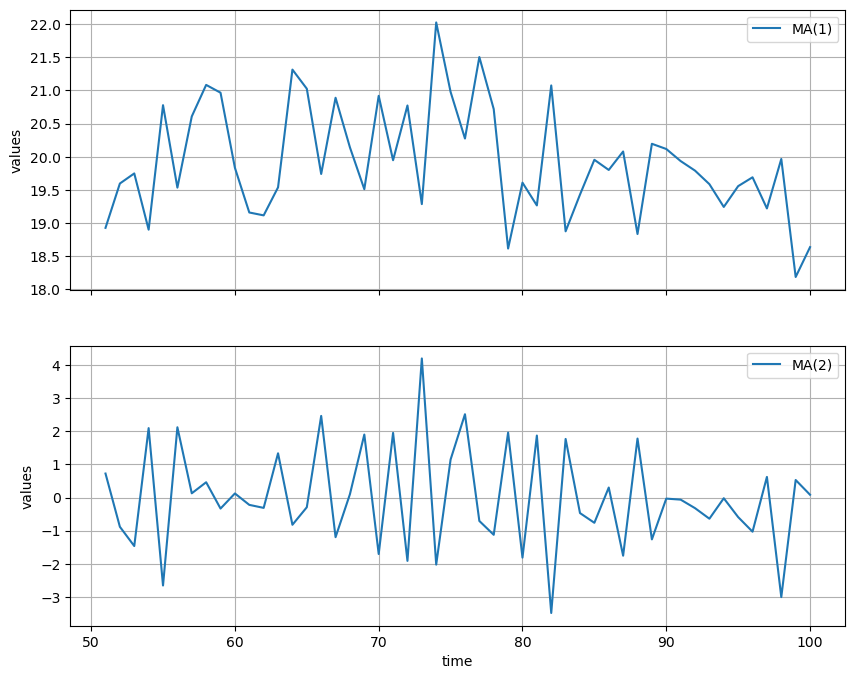

In [4]:
# create some indices for a hypotetical time series (that will be our "time-axis")
L=100 # set the number of time steps
t = [i for i in range(1,L+1)]

# Create normally distributed random number, with mean=0, and variance 1, or 0.8
mu, sigma1 = 0, 1
epsilon = np.random.normal(mu,sigma1,L)

# initialize some arrays to collect the results
MA1 = np.zeros((L,1))
MA2 = np.zeros((L,1))

# initialize AR1_t-1 with a random seed
MA1[0]=20 #AR1_0

MA2[0]=0
MA2[1]=AR1_0


# time step a made up AR(1) model, starting from index 1 (t), not 0 (0 is t-1)
for i in range(1,L):
    MA1[i] = 20 + 0.8*epsilon[i-1]

# time step a made up AR(2) model, starting from index 2 (t), not 1, 0 (1 is t-1; 0 is t-2)
for i in range(2,L):
    MA2[i] = epsilon[i]-epsilon[i-1]+0.8*epsilon[i-2]
    
# Plot it using a custom function
fig, (ax0, ax1) = plt.subplots(nrows=2, sharex=True, figsize=(10,8))
# plot the last half (the first half is mostly just busy converging to a stationary state)
ax0.plot(t[50:100],MA1[50:100], label="MA(1)") 
ax0.legend()
ax0.grid()
ax0.set_ylabel('values')
  
ax1.plot(t[50:100],MA2[50:100], label="MA(2)") 
ax1.legend()
ax1.grid()
ax1.set_ylabel('values')
ax1.set_xlabel('time')

plt.show()    

### The Lag Operator 'L'

Another common notation in time-series analysis makes use of the so-called [`lag operator`](https://en.wikipedia.org/wiki/Lag_operator). Given a time series $X={X_1, X_2,...}$, then the 'lag operator' **`L`** is defined such that 

$
LX_t=X_{t-1}
$

This can be generalized by raising the lag operator to an arbitrary interger power, such that: 

$
L^{k}X_t = X_{t-k}
$

(Noting that if $k < 0$, then $L^{-k} X_t = X_{t+k}). 

[With this notation](https://en.wikipedia.org/wiki/Autoregressive–moving-average_model), the AR(p) model could be written: 

$
\epsilon_t = \left(1 - \sum_{i=1}^{p} \phi_i L^i \right) X_t = \phi(L)X_t
$

where $\phi(L)$ now represents a polynomial:

$
\phi(L) = 1 - \sum_{i=1}^{p} L^i
$

and the MA(q) model becomes 

$
X_t = \left(1 + \sum_{i=1}^{q} \theta_i L^i \right) \epsilon_t = \theta(L)\epsilon_t
$

where $\theta(L)$ represent the polynomial

$
\theta(L) = 1 + \sum_{i=1}^q \theta_i L^i
$



<a id='ARMA'></a>
### ARMA(p,q) (Auto Regressive Moving Average Models)

[ARMA models are a combination of AR and MA models](https://en.wikipedia.org/wiki/Autoregressive–moving-average_model). The AR part involves regressing the variable on its own lagged (i.e., past) values. The MA part involves modeling the error term as a linear combination of error terms occurring contemporaneously and at various times in the past. ARMA requires two hyperparameters, ARMA(p, q), with (p) the orders of the AR model and (q) the order of the MA model. ARMA is applicable to stationary time series.

The ARMA model is then the combination of AR(p) and MA(q):

$
X_t = c + \epsilon_t + \sum_{i=1}^{p} \phi_i X_{t-i} +\sum_{i=1}^{q} \theta_i \epsilon_{t-i}
$

Given this definition, ARMA(1,1) would expand into: 

$
X_t = c + \epsilon_t + \phi_1 X_{t-1} + \theta_1 \epsilon_{t-1}.
$

One can also write the ARMA model using the lag operator (this is often the case in the literature). Assuming c=0, we can rearrange ARMA as:

$
X_t - \sum_{i=1}^{p} \phi_i X_{t-i} = \epsilon_t  + \sum_{i=1}^{q} \theta_i \epsilon_{t-i}
$

or 

$
\left( 1 - \sum_{i=1}^{p} \phi_i \right) X_t = \left( 1 + \sum_{i=1}^{q} \theta_i \right) \epsilon_t
$

which becomes simply: 

$
\phi(L)X_t = \theta(L)\epsilon_t
$

or also 

$
\frac{\phi(L)}{\theta(L)}X_t=\epsilon_t
$



<a id='ARIMA'></a>
### ARIMA(p,d,q) (Autoregressive integrated moving average)

[ARIMA](https://en.wikipedia.org/wiki/Autoregressive_integrated_moving_average) is the next step up from ARMA. The 'I' (which stands for 'integrated') in ARIMA refers to a differencing step used to eliminate non-stationarity in the original time-series, i.e. to detrend the data. The 'I' therefore indicates that the data values have been replaced with the difference between their values and the previous values (and this differencing process may have been performed more than once). 

ARIMA models can be used for non-stationary models, but only if the non-stationarity is due to a trend (including periodicity, seasonality), not if the non-stationarity affects other, higher, moments (e.g. variance, etc.). 

The parameters p, d, q needed in ARIMA(p,d,q) are non-negative integers. p and q are the orders of the AR and MA sub-models. The new parameter 'd' is the 'degree of differencing', which is the number of times the data have had past values subtracted. Therefore, ARIMA(1,0,0)=AR(1), ARIMA(0,0,1)=MA(1), ARIMA(1,0,1)=ARMA(1,1). 


Evolutions of ARIMA models are `seasonal ARIMA` models. These are typically written as: ARIMA(p,d,q)(P,D,Q)$_S$. 
The notation (P,D,Q)$_S$ refers to: 
- P: number of seasonal AR terms
- D: number of seasonal differences
- Q: number of seasonal MA terms
- S: length of the season (how many data points constitute a 'season', or a period)

For example, ARIMA(1,0,1)(2,1,0)$_{12}$ would imply the following: 
1. We see that D=1, so we need to first differnce our data. Since S=12, the season is 12 points long. We are probably dealing with monthly averaged data. So our first action will be do difference the data with another data point, 12 time steps before, to create a new 'stationary' data series that we are going to call $W_t$: 

$
X_t - X_{t-12} = W_t
$

2. Looking at the AR pieces now, p=1 and P=2. The p=1 term means that this is an AR(1) model so there will be $W_{t-1}$ term, with its associated $\phi_{1}$ parameter. The P=2 term, implies another two seasonally-shifted terms, by 1 x the season length, and 2 x the season length, or $W_{t-12}$ and $W_{t-(2\cdot 12=24)}$, and each will of course also get a new $\phi$ parameter. 
3. The MA part of the model only involves one error term, so just the $\theta_1 \epsilon_{t-1}$ term. 
   
ARIMA(1,0,1)(2,1,0)$_{12}$ therefore has the form:

$
X_t - X_{t-12} = W_t \\
W_t = c + \phi_1 W_{t-1} + \phi_2 W{t-12} + \phi_3 W_{t-(24)} + \theta_1 \epsilon_{t-1} + \epsilon_t
$
